In [7]:
!pip install qiskit
!pip install qiskit-ibm-runtime

In [19]:
from qiskit import QuantumRegister, ClassicalRegister, QuantumCircuit
from qiskit.providers.basic_provider import BasicSimulator
from qiskit.visualization import plot_histogram
# Creating registers
q = QuantumRegister(name='q', size=3)
c = ClassicalRegister(name='c', size=3)
# Creates the quantum circuit
teleport = QuantumCircuit(q, c)
# Step 0 - Instantiate qubit 0 in the state to be teleported:


teleport.h(0)
teleport.s(0)


teleport.barrier() # just a visual aid
# Step 1 - Make the shared entangled state in between qubit 1 and qubit 2

teleport.h(1)
teleport.cx(1,2)

teleport.barrier() # just a visual aid
# Step 2 & 3: Alice applies a series of gates on qubit 0 and qubit 1

teleport.cx(0, 1)
teleport.h(0)

# Step 4 - Alice measures qubit 0 and qubit 1

teleport.measure([0,1], [0,1])

# Step 5 - Bob applies a unitary transformation on his qubit
# based on the outcome of Alice's measurements

teleport.cx(1,2)
teleport.cz(0, 2)

teleport.barrier() # just a visual aid
# Visualizing your teleportation circuit


# Step 6 - Bob checks if he got the right state

teleport.sx(2)
teleport.measure(2, 2)

teleport.draw()


┌───┐┌───┐ ░            ░      ┌───┐┌─┐         ░          
q_0: ┤ H ├┤ S ├─░────────────░───■──┤ H ├┤M├──────■──░──────────
     └───┘└───┘ ░ ┌───┐      ░ ┌─┴─┐└┬─┬┘└╥┘      │  ░          
q_1: ───────────░─┤ H ├──■───░─┤ X ├─┤M├──╫───■───┼──░──────────
                ░ └───┘┌─┴─┐ ░ └───┘ └╥┘  ║ ┌─┴─┐ │  ░ ┌────┐┌─┐
q_2: ───────────░──────┤ X ├─░────────╫───╫─┤ X ├─■──░─┤ √X ├┤M├
                ░      └───┘ ░        ║   ║ └───┘    ░ └────┘└╥┘
c: 3/═════════════════════════════════╩═══╩═══════════════════╩═
                                      1   0                   2

The counts for circuit teleport are: {'011': 2069, '010': 2022, '000': 2052, '001': 2049}


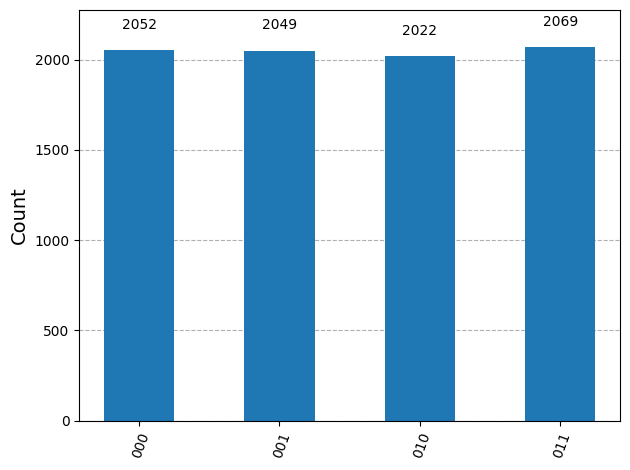

In [13]:
backend = BasicSimulator()
result = backend.run(teleport, shots=8192).result()
counts = result.get_counts()
print(f"The counts for circuit teleport are: {counts}")
plot_histogram(counts)

Lors de la mesure par Alice de ses deux qubits, le résultat binaire 00 apparaît dans 25 % des cas. Dans cette situation précise, l'état est directement transféré chez Bob sans modification. Dans les 75 % de cas restants, Bob doit appliquer une transformation unitaire spécifique dictée par le résultat d'Alice. Après cette correction, l'état du qubit de Bob devient rigoureusement égal à |ϕ⟩.

Pour valider expérimentalement le protocole, on répète l'opération de nombreuses fois. En accumulant les probabilités de ces mesures, Bob reconstruit mathématiquement la matrice de densité de l'état reçu. Il la compare enfin avec l'état initial d'Alice.